In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Ajoute le dossier src au chemin d'importation local
sys.path.insert(0, str(Path("../src").resolve()))

from simu_lockin_kk.analysis.kramers_kronig import KramersKronigAnalyzer
from simu_lockin_kk.config import KKConfig, LockInConfig, NoiseConfig, RCCircuitConfig
from simu_lockin_kk.physics.rc_circuit import RCCircuit
from simu_lockin_kk.signal.lockin import demodulate_sweep
from simu_lockin_kk.visualization.plots import (
    plot_bode,
    plot_extrapolated_points,
    plot_kramers_kronig_comparison,
    plot_methods_comparison,
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
print("Environnement et modules chargés.")

Environnement et modules chargés.


In [2]:
rc_cfg = RCCircuitConfig(R=1000.0, C=1e-6, num_freqs=150, f_min=0.1, f_max=1e5)
circuit = RCCircuit(rc_cfg)

# Bruit blanc ajouté sur la sortie simulée pour se rapprocher d'une acquisition réelle
noise_cfg = NoiseConfig(noise_type="white", std_white=0.05, seed=42)

print(f"R = {circuit.R:.1f} Ω | C = {circuit.C*1e6:.2f} µF | fc = {circuit.fc:.2f} Hz")

R = 1000.0 Ω | C = 1.00 µF | fc = 159.15 Hz


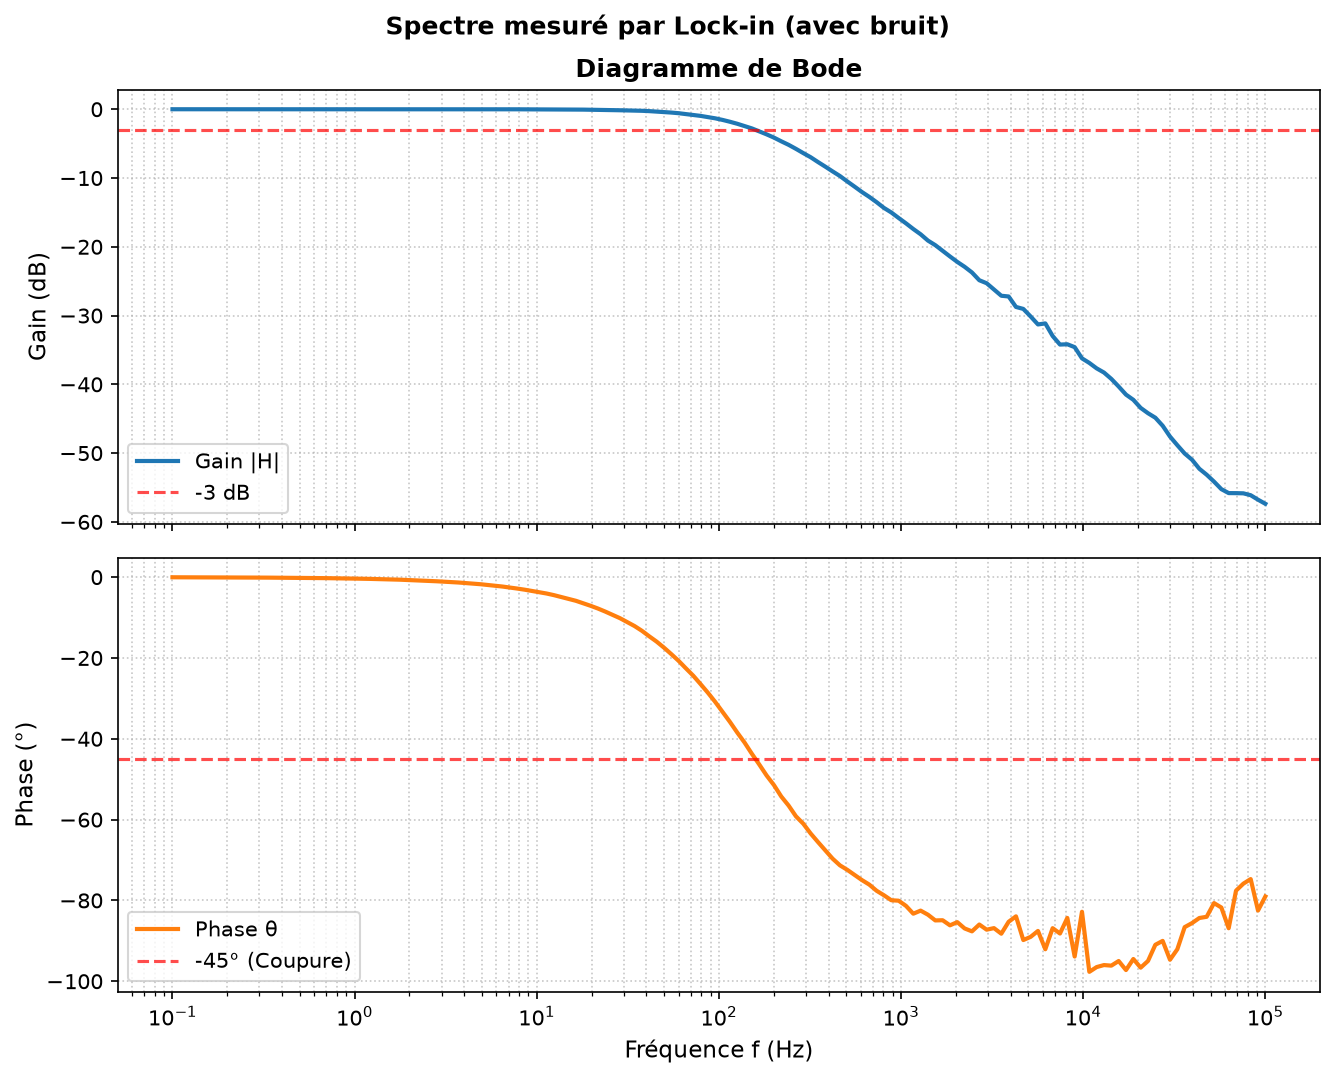

In [ ]:
spectrum_lockin = demodulate_sweep(
    rc_config=rc_cfg,
    duration=0.04,
    fs=1e5,
    noise_cfg=noise_cfg,
    lpf_cutoff=10.0,
    lpf_order=2,
    lpf_type='moving_average'
)

fig_bode = plot_bode(spectrum_lockin, use_omega=False)
plt.suptitle("Spectre mesuré par Lock-in (avec bruit)", y=1.02, fontweight="bold")
plt.show()

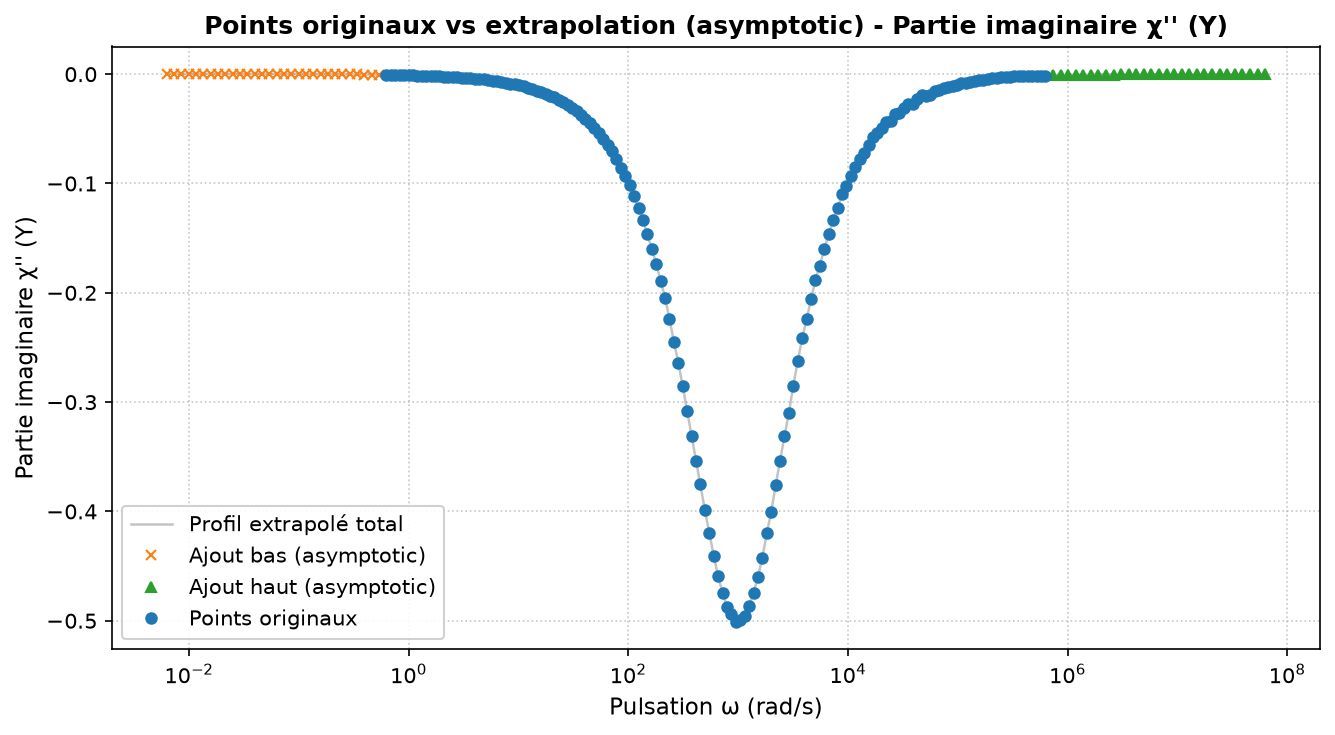

In [4]:
cfg_maclaurin = KKConfig(
    integration_method="cauchy_maclaurin",
    extrapolation="asymptotic",
)

fig_extrap_pts = plot_extrapolated_points(
    spectrum_lockin,
    component="imag",
    kk_cfg=cfg_maclaurin,
    use_omega=True,
)
plt.show()

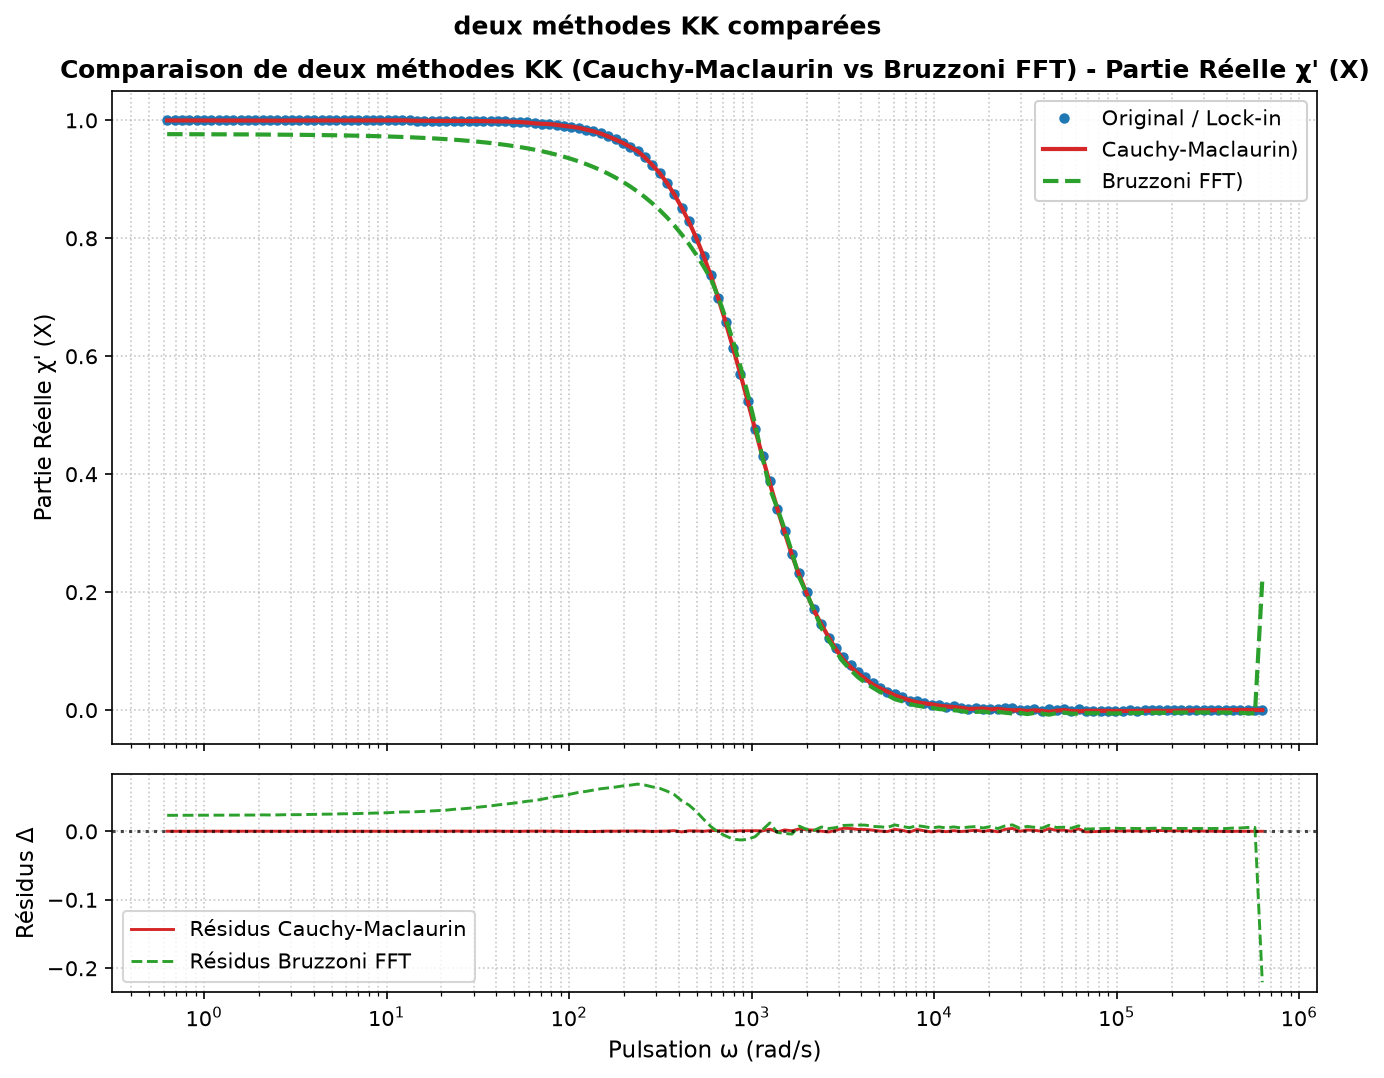

In [7]:
# VP cauchy
cfg_maclaurin = KKConfig(
    integration_method="cauchy_maclaurin",
    extrapolation="asymptotic",
)

# FFT Bruzo
cfg_bruzzoni = KKConfig(
    integration_method="bruzzoni_fft",
    extrapolation="none",
)

analyzer_mac = KramersKronigAnalyzer(cfg_maclaurin)
analyzer_bruz = KramersKronigAnalyzer(cfg_bruzzoni)

res_mac = analyzer_mac.analyze(spectrum_lockin, target="real")
res_bruz = analyzer_bruz.analyze(spectrum_lockin, target="real")


fig_comp = plot_methods_comparison(
    spectrum_lockin,
    cfg_a=cfg_maclaurin,
    cfg_b=cfg_bruzzoni,
    label_a="Cauchy-Maclaurin",
    label_b="Bruzzoni FFT",
    target="real",
    use_omega=True,
)
plt.suptitle("deux méthodes KK comparées", y=1.02, fontweight="bold")
plt.show()